# Part 2: Linear Regression

Run top to bottom. `FAST=0` runs at full scale (see README).

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt
import mlcore as mc

FAST = mc.fast_mode()  # R2: FAST=0 for full scale
rng = np.random.default_rng(mc.SEED)  # R2 seed; experiments use mc.rng_for(tag)
print(f"FAST={FAST}")

FAST=True


## 2.2 Five solvers

All five minimize $E_{in}(w)=\frac1N\lVert Xw-y\rVert^2$:
- (a) the lecture-slide formula $w=(X^TX)^{-1}X^Ty$ with `np.linalg.inv`;
- (b) the pseudo-inverse $X^\dagger y$ through the SVD;
- (c) least squares through QR / LAPACK `lstsq`;
- (d) batch gradient descent with our gradient $\nabla E_{in}=\frac2N X^T(Xw-y)$ and step $\eta=1/L$, $L=2\lambda_{max}(X^TX)/N$;
- (e) `scipy.optimize.minimize(method="L-BFGS-B")` with the same analytic gradient.

The gradient is checked against central differences first.

In [2]:
rng = mc.rng_for("2_2")
X = mc.add_bias(rng.standard_normal((500, 10)))
y = X @ rng.standard_normal(11) + 0.1 * rng.standard_normal(500)
loss_grad = lambda w: mc.linreg_loss_grad(w, X, y)  # noqa: E731

gc = mc.gradient_check(lambda w: loss_grad(w)[0], lambda w: loss_grad(w)[1], rng.standard_normal(11))
print(f"gradient check: relative error {gc:.2e}")
assert gc < 1e-6

w_ls = mc.solve_lstsq(X, y)
w_gd, gd_hist = mc.gradient_descent(loss_grad, np.zeros(11), 1 / mc.lipschitz_linreg(X), 100_000, tol=1e-10)
w_lb, lb_res = mc.lbfgs(loss_grad, np.zeros(11), tol=1e-14)
solutions = {
    "(a) inv(X^T X) X^T y": mc.solve_normal_inv(X, y),
    "(b) pinv via SVD": mc.solve_pinv_svd(X, y),
    "(c) QR": mc.solve_qr(X, y),
    "(c) lstsq": w_ls,
    "(d) batch GD": w_gd,
    "(e) L-BFGS-B": w_lb,
}
print(f"N = 500, d = 10, kappa(X) = {np.linalg.cond(X):.2f}; differences against lstsq:")
for name, w in solutions.items():
    print(f"  {name:<22} max|w - w_lstsq| = {np.max(np.abs(w - w_ls)):.1e}")
print(f"GD: {gd_hist.size - 1} iterations to ||grad|| <= 1e-10; L-BFGS-B: {lb_res.nit} iterations")
assert all(np.max(np.abs(w - w_ls)) < 1e-8 for w in solutions.values())

gradient check: relative error 3.36e-10
N = 500, d = 10, kappa(X) = 1.32; differences against lstsq:
  (a) inv(X^T X) X^T y   max|w - w_lstsq| = 1.8e-15
  (b) pinv via SVD       max|w - w_lstsq| = 6.7e-16
  (c) QR                 max|w - w_lstsq| = 1.4e-15
  (c) lstsq              max|w - w_lstsq| = 0.0e+00
  (d) batch GD           max|w - w_lstsq| = 2.6e-11
  (e) L-BFGS-B           max|w - w_lstsq| = 1.4e-09
GD: 28 iterations to ||grad|| <= 1e-10; L-BFGS-B: 10 iterations


**Interpretation.** The analytic gradient matches central differences ($3.4\times10^{-10}$), and all five solvers agree with `lstsq`. The direct ones agree to $\le1.8\times10^{-15}$, GD to $2.6\times10^{-11}$ and L-BFGS to $1.4\times10^{-9}$, the size of their stopping tolerances.

## 2.3 ⋆ Ill-conditioning

$X=[1,\,x_1,\,x_2]$ with $x_1\sim N(0,1)$, $x_2=x_1+\delta u$, $u\sim N(0,1)$, $\delta\in\{10^{-1},\dots,10^{-8}\}$; $N=100$, $w^*=(0.5,1,2)$, noise $\sigma=0.01$ plus a noiseless run, 100 runs per $\delta$ (DECISIONS row 13).
Key identity: $\kappa(X^TX)=\kappa(X)^2$, so any method that forms $X^TX$ works with a problem squared in difficulty.

To separate numerical from statistical error, we compare every solver with an exact reference. Since $X=BT$ with the well-conditioned $B=[1,x_1,u]$ and $T=\begin{psmallmatrix}1&0&0\\0&1&1\\0&0&\delta\end{psmallmatrix}$, the least-squares solution is $w=T^{-1}\,\mathrm{lstsq}(B,y)$, accurate to machine precision.

In [3]:
import time
import warnings

DELTAS = 10.0 ** -np.arange(1, 9)
RUNS_23, N_23 = 100, 100
W_STAR = np.array([0.5, 1.0, 2.0])
EPS = np.finfo(float).eps


def make_data(rng, delta, sigma, N=N_23):
    x1, u = rng.standard_normal(N), rng.standard_normal(N)
    X = np.column_stack([np.ones(N), x1, x1 + delta * u])
    B = np.column_stack([np.ones(N), x1, u])
    return X, B, X @ W_STAR + sigma * rng.standard_normal(N)


def reference(B, y, delta):
    # exact solution via the well-conditioned basis B
    v = mc.solve_lstsq(B, y)
    w2 = v[2] / delta
    return np.array([v[0], v[1] - w2, w2])


X, B, y = make_data(mc.rng_for("2_3_check"), 0.1, 0.01)
print(f"reference vs lstsq at delta = 0.1: {np.max(np.abs(reference(B, y, 0.1) - mc.solve_lstsq(X, y))):.1e}")
assert np.max(np.abs(reference(B, y, 0.1) - mc.solve_lstsq(X, y))) < 1e-10

reference vs lstsq at delta = 0.1: 4.2e-15


In [4]:
SOLVERS = {
    "inv": mc.solve_normal_inv,
    "pinv": mc.solve_pinv_svd,
    "qr": mc.solve_qr,
    "lstsq": mc.solve_lstsq,
    "L-BFGS": lambda X, y: mc.lbfgs(lambda w: mc.linreg_loss_grad(w, X, y), np.zeros(3), tol=1e-14)[0],
}
METRICS = ("total", "num", "resid", "sum")
rng = mc.rng_for("2_3")
res23, failures, gd_data = {}, {}, {"X": [], "y": [], "ref": []}
t0 = time.perf_counter()
for sigma in (0.01, 0.0):
    kappa = np.zeros((DELTAS.size, RUNS_23))
    out = {s: {k: np.full((DELTAS.size, RUNS_23), np.nan) for k in METRICS} for s in SOLVERS}
    for i, delta in enumerate(DELTAS):
        Xd, yd, rd = [], [], []
        for r in range(RUNS_23):
            X, B, y = make_data(rng, delta, sigma)
            w_ref = reference(B, y, delta)
            kappa[i, r] = np.linalg.cond(X)
            Xd.append(X), yd.append(y), rd.append(w_ref)
            for name, solve in SOLVERS.items():
                try:
                    with warnings.catch_warnings(), np.errstate(all="ignore"):
                        warnings.simplefilter("ignore")
                        w = solve(X, y)
                except np.linalg.LinAlgError:
                    failures[(name, sigma, delta)] = failures.get((name, sigma, delta), 0) + 1
                    continue
                out[name]["total"][i, r] = np.linalg.norm(w - W_STAR)
                out[name]["num"][i, r] = np.linalg.norm(w - w_ref) / np.linalg.norm(w_ref)
                out[name]["resid"][i, r] = np.linalg.norm(X @ w - y) / np.sqrt(N_23)
                out[name]["sum"][i, r] = abs(w[1] + w[2] - W_STAR[1] - W_STAR[2])
        if sigma == 0.01:
            gd_data["X"].append(np.stack(Xd)), gd_data["y"].append(np.stack(yd)), gd_data["ref"].append(np.stack(rd))
    res23[sigma] = {"kappa": kappa, "out": out}
print(f"{2 * DELTAS.size * RUNS_23} datasets x {len(SOLVERS)} solvers in {time.perf_counter() - t0:.1f} s; "
      f"LinAlgError (singular matrix) counts: {failures if failures else 'none'}")


def gmean(a):
    # geometric mean over runs; zeros floored at 1e-17
    return np.exp(np.nanmean(np.log(np.maximum(a, 1e-17)), axis=1))


K = gmean(res23[0.01]["kappa"])
print(f"\n{'delta':>7}{'kappa(X)':>11} | relative numerical error ||w - w_ref|| / ||w_ref|| (sigma = 0.01, geometric mean of 100 runs)")
print(f"{'':>18} | " + "".join(f"{s:>10}" for s in SOLVERS) + f"{'kappa*eps':>11}{'kappa^2*eps':>13}")
for i, delta in enumerate(DELTAS):
    row = "".join(f"{gmean(res23[0.01]['out'][s]['num'])[i]:>10.1e}" for s in SOLVERS)
    print(f"{delta:>7.0e}{K[i]:>11.2e} | {row}{K[i] * EPS:>11.1e}{K[i] ** 2 * EPS:>13.1e}")
print(f"\n{'delta':>7} | total error ||w - w*||: lstsq sigma=0.01 / lstsq sigma=0 / inv sigma=0 | |w1+w2 - 3| lstsq | residual lstsq / inv")
for i, delta in enumerate(DELTAS):
    o, o0 = res23[0.01]["out"], res23[0.0]["out"]
    print(f"{delta:>7.0e} | {gmean(o['lstsq']['total'])[i]:>10.2e} {gmean(o0['lstsq']['total'])[i]:>10.2e} {gmean(o0['inv']['total'])[i]:>10.2e}"
          f" | {gmean(o['lstsq']['sum'])[i]:>9.1e} | {np.nanmean(o['lstsq']['resid'][i]):.5f} / {np.nanmean(o['inv']['resid'][i]):.3g}")

1600 datasets x 5 solvers in 0.5 s; LinAlgError (singular matrix) counts: none

  delta   kappa(X) | relative numerical error ||w - w_ref|| / ||w_ref|| (sigma = 0.01, geometric mean of 100 runs)
                   |        inv      pinv        qr     lstsq    L-BFGS  kappa*eps  kappa^2*eps
  1e-01   2.06e+01 |    5.4e-14   2.3e-15   2.2e-15   2.3e-15   2.2e-10    4.6e-15      9.4e-14
  1e-02   2.03e+02 |    5.3e-12   2.4e-14   2.5e-14   2.4e-14   2.3e-09    4.5e-14      9.2e-12
  1e-03   2.07e+03 |    6.3e-10   2.3e-13   2.3e-13   2.1e-13   8.0e-08    4.6e-13      9.6e-10
  1e-04   1.99e+04 |    4.5e-08   2.0e-12   1.9e-12   2.1e-12   3.0e-05    4.4e-12      8.8e-08
  1e-05   2.05e+05 |    3.2e-06   2.6e-11   2.6e-11   2.6e-11   2.2e-01    4.5e-11      9.3e-06
  1e-06   2.02e+06 |    3.4e-04   3.4e-10   3.4e-10   3.4e-10   8.6e-01    4.5e-10      9.1e-04
  1e-07   2.03e+07 |    3.6e-02   2.3e-09   2.3e-09   2.3e-09   1.0e+00    4.5e-09      9.2e-02
  1e-08   2.03e+08 |    1.0e+00   2.8

In [5]:
# GD iterations to relative error 1e-6
CAP = 10**5 if FAST else 10**6
gd_k, gd_iters, gd_num = [], [], []
t0 = time.perf_counter()
for i, delta in enumerate(DELTAS):
    X, y, W_ref = gd_data["X"][i], gd_data["y"][i], gd_data["ref"][i]
    eta = np.array([1.0 / mc.lipschitz_linreg(Xr) for Xr in X])
    W, iters = mc.gd_linreg_batched(X, y, eta, CAP, w_ref=W_ref, rtol=1e-6, check_every=100)
    gd_k.append(K[i]), gd_iters.append(iters)
    gd_num.append(np.linalg.norm(W - W_ref, axis=1) / np.linalg.norm(W_ref, axis=1))
    print(f"delta = {delta:.0e}, kappa = {K[i]:.2e}: median iterations {np.median(np.where(iters > 0, iters, CAP)):>9.0f}, "
          f"capped {np.sum(iters < 0):3d}/100, relative error at stop (median) {np.median(gd_num[-1]):.1e}")
    if np.all(iters < 0):
        print(f"every run capped at {CAP:.0e}; smaller deltas ({', '.join(f'{d:.0e}' for d in DELTAS[i + 1:])}) not run: they need even more")
        break
print(f"GD sweep: {time.perf_counter() - t0:.1f} s (cap {CAP:.0e})")
if not FAST:
    mc.save_cache("2_3_gd_iters", kappa=np.array(gd_k), iters=np.array(gd_iters), cap=CAP)

delta = 1e-01, kappa = 2.06e+01: median iterations      5400, capped   0/100, relative error at stop (median) 9.0e-07


delta = 1e-02, kappa = 2.03e+02: median iterations    100000, capped 100/100, relative error at stop (median) 2.7e-02
every run capped at 1e+05; smaller deltas (1e-03, 1e-04, 1e-05, 1e-06, 1e-07, 1e-08) not run: they need even more
GD sweep: 2.7 s (cap 1e+05)


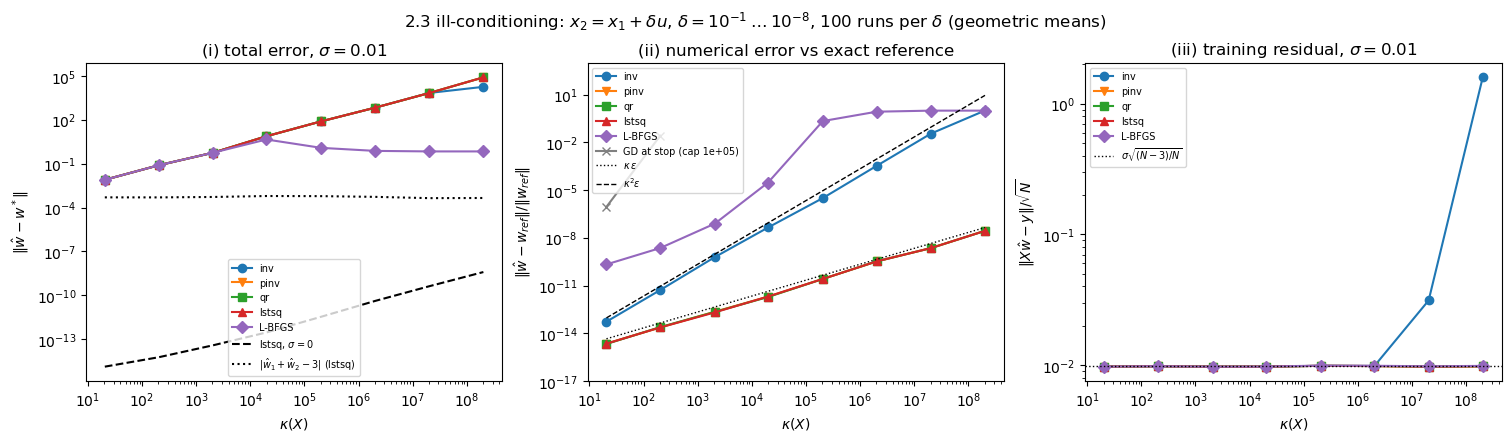

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3), constrained_layout=True)
markers = dict(zip(list(SOLVERS) + ["GD"], "ovs^Dx"))
o, o0 = res23[0.01]["out"], res23[0.0]["out"]
ax = axes[0]
for s in SOLVERS:
    ax.loglog(K, gmean(o[s]["total"]), marker=markers[s], label=s)
ax.loglog(K, gmean(o0["lstsq"]["total"]), "k--", label=r"lstsq, $\sigma = 0$")
ax.loglog(K, gmean(o["lstsq"]["sum"]), "k:", label=r"$|\hat w_1+\hat w_2 - 3|$ (lstsq)")
ax.set(xlabel=r"$\kappa(X)$", ylabel=r"$\Vert \hat w - w^* \Vert$", title=r"(i) total error, $\sigma = 0.01$")
ax.legend(fontsize=7)
ax = axes[1]
for s in SOLVERS:
    ax.loglog(K, gmean(o[s]["num"]), marker=markers[s], label=s)
ax.loglog(gd_k, [np.median(g) for g in gd_num], marker="x", color="gray", label=f"GD at stop (cap {CAP:.0e})")
ax.loglog(K, K * EPS, "k:", lw=1, label=r"$\kappa\,\epsilon$")
ax.loglog(K, K**2 * EPS, "k--", lw=1, label=r"$\kappa^2\epsilon$")
ax.set(xlabel=r"$\kappa(X)$", ylabel=r"$\Vert \hat w - w_{ref} \Vert / \Vert w_{ref} \Vert$",
       title="(ii) numerical error vs exact reference", ylim=(1e-17, 1e3))
ax.legend(fontsize=7)
ax = axes[2]
for s in SOLVERS:
    ax.loglog(K, np.nanmean(o[s]["resid"], axis=1), marker=markers[s], label=s)
ax.axhline(0.01 * np.sqrt((N_23 - 3) / N_23), color="k", ls=":", lw=1, label=r"$\sigma\sqrt{(N-3)/N}$")
ax.set(xlabel=r"$\kappa(X)$", ylabel=r"$\Vert X\hat w - y \Vert / \sqrt{N}$", title=r"(iii) training residual, $\sigma = 0.01$")
ax.legend(fontsize=7)
fig.suptitle(rf"2.3 ill-conditioning: $x_2 = x_1 + \delta u$, $\delta = 10^{{-1}}\dots10^{{-8}}$, {RUNS_23} runs per $\delta$ (geometric means)")
mc.savefig(fig, "2_3_coef_error")
plt.show()

**Interpretation.** Against the exact reference, QR, SVD and `lstsq` track $\kappa\epsilon$ (down to $2.8\times10^{-8}$ at $\kappa=2\times10^8$), while `inv` tracks $\kappa^2\epsilon$ and reaches 100% error, because forming $X^TX$ squares the condition number. L-BFGS stalls from $\kappa\approx2\times10^5$. The statistical error grows with $\kappa$ for every solver, but $w_1+w_2$ stays determined to $5\times10^{-4}$ and the residual stays at the noise level, so only the direction along $x_1-x_2$ is lost. We would ship QR or `lstsq`; the slide formula is only safe for well-conditioned problems.

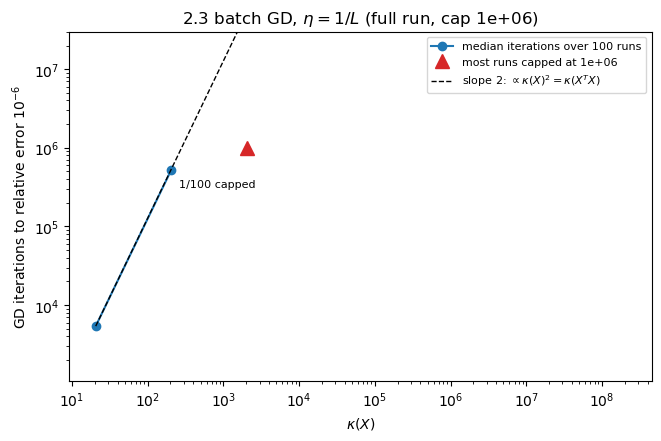

plotted from: full run, cap 1e+06; kappa = [  20.6  203.4 2074. ], median iterations = [   5400.  516600. 1000000.], capped runs = [  0   1 100]
iteration ratio between the first two kappas: 95.7x vs kappa^2 ratio 97.7x


In [7]:
full = mc.load_full_cache("2_3_gd_iters") if FAST else None
src = full if full is not None else {"kappa": np.array(gd_k), "iters": np.array(gd_iters), "cap": CAP}
cap = int(src["cap"])
label = f"full run, cap {cap:.0e}" if full is not None or not FAST else f"FAST run, cap {cap:.0e}"
fig, ax = plt.subplots(figsize=(6.5, 4.3), constrained_layout=True)
kk, it = src["kappa"], src["iters"]
conv = np.array([np.mean(row > 0) >= 0.5 for row in it])           # the median run converged
n_cap = np.array([np.sum(row < 0) for row in it])
med = np.array([np.median(np.where(row > 0, row, cap)) for row in it])
ax.loglog(kk[conv], med[conv], "o-", label="median iterations over 100 runs")
for k_, m_, c_ in zip(kk[conv], med[conv], n_cap[conv]):
    if c_:
        ax.annotate(f"{c_}/100 capped", (k_, m_), textcoords="offset points", xytext=(6, -12), fontsize=8)
if (~conv).any():
    ax.loglog(kk[~conv], np.full((~conv).sum(), cap), "^", ms=10, color="C3", label=f"most runs capped at {cap:.0e}")
kref = np.geomspace(kk[0], K[-1], 50)
ax.loglog(kref, med[0] * (kref / kk[0]) ** 2, "k--", lw=1, label=r"slope 2: $\propto\kappa(X)^2=\kappa(X^TX)$")
ax.set(xlabel=r"$\kappa(X)$", ylabel="GD iterations to relative error $10^{-6}$", ylim=(None, cap * 30),
       title=f"2.3 batch GD, $\\eta = 1/L$ ({label})")
ax.legend(fontsize=8)
mc.savefig(fig, "2_3_gd_iterations")
plt.show()
print(f"plotted from: {label}; kappa = {np.round(kk, 1)}, median iterations = {med}, capped runs = {n_cap}")
if conv.sum() >= 2:
    print(f"iteration ratio between the first two kappas: {med[1] / med[0]:.1f}x vs kappa^2 ratio {(kk[1] / kk[0]) ** 2:.1f}x")

**Interpretation.** GD needs 5 400 iterations at $\kappa=20.6$ and 516 600 at $\kappa=203$, a ratio of 95.7 against the predicted $\kappa^2$ ratio of 97.7, since each step contracts the error by $1-1/\kappa(X^TX)$. At $\kappa=2074$ every run hits the $10^6$ cap.

## 2.4 ⋆ Learning curves: theory versus simulation

Linear target with Gaussian inputs: $x\sim N(0,I_d)$, $d=10$, $y=w^{*T}[1,x]+\epsilon$, $\sigma=0.5$, 500 runs per $N\in\{12,\dots,200\}$.
LFD: $E[E_{in}]=\sigma^2\left(1-\frac{d+1}{N}\right)$ (exact) and $E[E_{out}]\approx\sigma^2\left(1+\frac{d+1}{N}\right)$.
Because $E[x]=0$ and $\mathrm{Cov}[x]=I$, the out-of-sample error is analytic: $E_{out}=\sigma^2+(\hat b-b)^2+\lVert\hat w-w^*\rVert^2$, so no test sample is needed. Each $N$ is one batched least-squares call (`mc.lstsq_batched`).
$E_{out}$ does not depend on $w^*$ for a realizable linear target, so one fixed $w^*$ is used.

In [8]:
d, sigma = 10, 0.5
N_GRID = np.arange(12, 201)
RUNS_24 = 500
rng = mc.rng_for("2_4")
w_star = rng.standard_normal(d + 1)
ein_m, ein_se, eout_m, eout_se, eout_md = (np.zeros(N_GRID.size) for _ in range(5))
for i, N in enumerate(N_GRID):
    Xb = np.concatenate([np.ones((RUNS_24, N, 1)), rng.standard_normal((RUNS_24, N, d))], axis=2)
    y = Xb @ w_star + sigma * rng.standard_normal((RUNS_24, N))
    W = mc.lstsq_batched(Xb, y)
    ein = np.mean((np.einsum("rnm,rm->rn", Xb, W) - y) ** 2, axis=1)
    eout = sigma**2 + np.sum((W - w_star) ** 2, axis=1)
    (ein_m[i], ein_se[i]), (eout_m[i], eout_se[i]) = mc.mean_se(ein), mc.mean_se(eout)
    eout_md[i] = np.median(eout)
lfd_in = sigma**2 * (1 - (d + 1) / N_GRID)
lfd_out = sigma**2 * (1 + (d + 1) / N_GRID)
print(f"{'N':>4} {'mean Ein':>18} {'LFD Ein':>8} {'mean Eout':>22} {'median Eout':>12} {'LFD Eout':>9}")
for N in (12, 13, 14, 16, 20, 30, 50, 100, 200):
    i = N - 12
    print(f"{N:>4} {ein_m[i]:>9.4f} ± {ein_se[i]:.4f} {lfd_in[i]:>8.4f} {eout_m[i]:>12.4g} ± {eout_se[i]:<8.3g} {eout_md[i]:>12.4f} {lfd_out[i]:>9.4f}")
z_in = np.abs(ein_m - lfd_in) / ein_se
print(f"Ein: max |mean - LFD| / SE over all {N_GRID.size} values of N = {z_in.max():.2f} (median {np.median(z_in):.2f})")
z_out = (eout_m - lfd_out) / eout_se
print(f"Eout: (mean - LFD) / SE at N = 20, 30, 50, 100, 200: {np.round(z_out[[8, 18, 38, 88, 188]], 1)}")

   N           mean Ein  LFD Ein              mean Eout  median Eout  LFD Eout
  12    0.0199 ± 0.0013   0.0208        8.339 ± 2.06           2.0386    0.4792
  13    0.0395 ± 0.0016   0.0385        3.532 ± 0.472          1.3047    0.4615
  14    0.0508 ± 0.0018   0.0536        1.587 ± 0.095          1.0574    0.4464
  16    0.0797 ± 0.0023   0.0781       0.9723 ± 0.0437         0.7267    0.4219
  20    0.1115 ± 0.0024   0.1125       0.5906 ± 0.0111         0.5362    0.3875
  30    0.1592 ± 0.0023   0.1583        0.401 ± 0.0039         0.3795    0.3417
  50    0.1938 ± 0.0020   0.1950       0.3226 ± 0.00165        0.3143    0.3050
 100    0.2226 ± 0.0016   0.2225       0.2817 ± 0.000642       0.2795    0.2775
 200    0.2360 ± 0.0011   0.2362       0.2648 ± 0.000283       0.2643    0.2637
Ein: max |mean - LFD| / SE over all 189 values of N = 2.74 (median 0.51)
Eout: (mean - LFD) / SE at N = 20, 30, 50, 100, 200: [18.2 15.2 10.7  6.6  3.6]


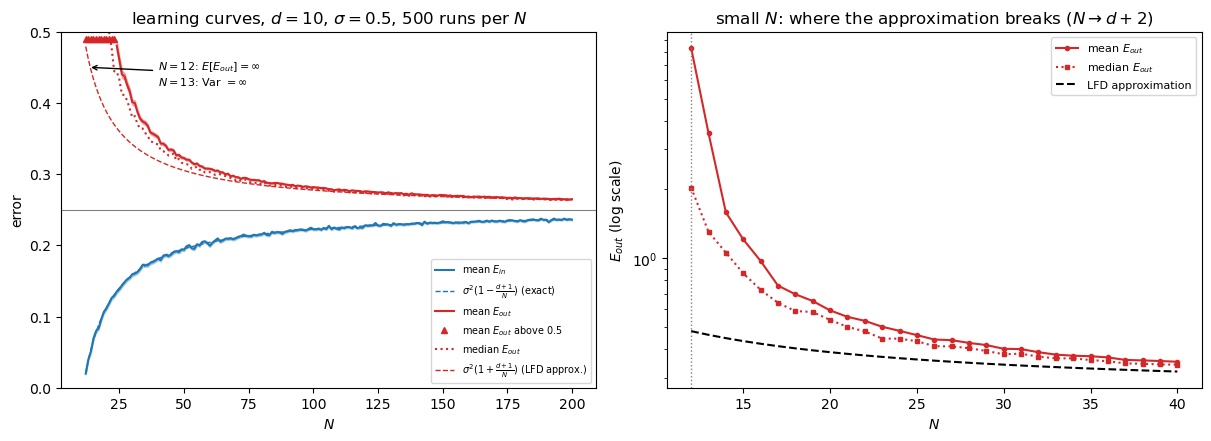

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3), constrained_layout=True)
ax = axes[0]
top = 2 * sigma**2
ax.plot(N_GRID, ein_m, color="C0", label="mean $E_{in}$")
ax.fill_between(N_GRID, ein_m - ein_se, ein_m + ein_se, color="C0", alpha=0.3)
ax.plot(N_GRID, lfd_in, "C0--", lw=1, label=r"$\sigma^2(1-\frac{d+1}{N})$ (exact)")
inside = eout_m < top
ax.plot(N_GRID[inside], eout_m[inside], color="C3", label="mean $E_{out}$")
ax.fill_between(N_GRID[inside], (eout_m - eout_se)[inside], np.minimum(eout_m + eout_se, top)[inside], color="C3", alpha=0.3)
ax.plot(N_GRID[~inside], np.full((~inside).sum(), top * 0.98), "^", color="C3", ms=5, label=f"mean $E_{{out}}$ above {top}")
ax.plot(N_GRID, eout_md, color="C3", ls=":", label="median $E_{out}$")
ax.plot(N_GRID, lfd_out, "C3--", lw=1, label=r"$\sigma^2(1+\frac{d+1}{N})$ (LFD approx.)")
ax.axhline(sigma**2, color="gray", lw=0.8)
ax.annotate(r"$N=12$: $E[E_{out}]=\infty$" "\n" r"$N=13$: Var $=\infty$", xy=(13, top * 0.9), xytext=(40, top * 0.85),
            arrowprops=dict(arrowstyle="->"), fontsize=8)
ax.set(xlabel="$N$", ylabel="error", ylim=(0, top), title=rf"learning curves, $d = {d}$, $\sigma = {sigma}$, {RUNS_24} runs per $N$")
ax.legend(fontsize=7, loc="lower right")
ax = axes[1]
small = N_GRID <= 40
ax.semilogy(N_GRID[small], eout_m[small], "o-", color="C3", ms=3, label="mean $E_{out}$")
ax.semilogy(N_GRID[small], eout_md[small], "s:", color="C3", ms=3, label="median $E_{out}$")
ax.semilogy(N_GRID[small], lfd_out[small], "k--", label="LFD approximation")
ax.axvline(d + 2, color="gray", ls=":", lw=1)
ax.set(xlabel="$N$", ylabel="$E_{out}$ (log scale)", title=r"small $N$: where the approximation breaks ($N \to d+2$)")
ax.legend(fontsize=8)
mc.savefig(fig, "2_4_learning_curves")
plt.show()

**Interpretation.** The $E_{in}$ formula is exact: over 189 values of $N$ the mean is within 2.7 SE of it. The $E_{out}$ formula underestimates, by 18 SE at $N=20$ and still 3.6 SE at $N=200$. Near $N=d+1$, rare and nearly singular designs dominate ($N=12$: mean $8.3\pm2.1$, median 2.0), because $E[(X^TX)^{-1}]$ grows like $1/(N-d-2)$, which the $1/N$ approximation misses.

## 2.5 Real data: California housing

`fetch_california_housing` (target in \$100k). 20% test split (tag `2_5_split`), standardization on the training split, least squares. The test set is used once (`# TEST`).

In [10]:
from sklearn.datasets import fetch_california_housing   # data loading only (R1)

cal = fetch_california_housing()
Xc, yc, names_c = cal.data, cal.target, list(cal.feature_names)
tr25, te25 = mc.random_split(yc.size, 0.2, mc.rng_for("2_5_split"))
Z25, prm25 = mc.standardize(Xc[tr25])
X25, y25 = mc.add_bias(Z25), yc[tr25]
w25 = mc.solve_lstsq(X25, y25)
print(f"train {tr25.size}, test {te25.size}; {np.mean(y25 >= 5.0):.1%} of training targets sit at the cap of 5.0 ($500k)")
print(f"training MSE {mc.mse(y25, X25 @ w25):.4f}, training R^2 {mc.r2_score(y25, X25 @ w25):.4f}")

train 16512, test 4128; 5.0% of training targets sit at the cap of 5.0 ($500k)
training MSE 0.5270, training R^2 0.6062


In [11]:
# TEST: evaluated once
X25te, y25te = mc.add_bias(mc.apply_standardize(Xc[te25], prm25)), yc[te25]
pred25 = X25te @ w25
sq = (pred25 - y25te) ** 2
print("test MSE {:.4f} ± {:.4f}".format(*mc.mean_se(sq)) + f", test R^2 {mc.r2_score(y25te, pred25):.4f}")
res25 = y25te - pred25
print(f"test residuals: mean {res25.mean():+.3f}; mean residual for districts at the cap: {res25[y25te >= 5.0].mean():+.3f} "
      f"({np.sum(y25te >= 5.0)} districts); predictions outside the observed range [0.15, 5.0]: {np.mean((pred25 < 0.15) | (pred25 > 5.0)):.1%}")

test MSE 0.5147 ± 0.0182, test R^2 0.6054
test residuals: mean -0.009; mean residual for districts at the cap: +1.077 (167 districts); predictions outside the observed range [0.15, 5.0]: 1.8%


In [12]:
# coefficients and feature correlations
corr_y = np.array([np.corrcoef(Xc[tr25][:, j], y25)[0, 1] for j in range(8)])
print(f"{'feature':<12}{'coef (per sd)':>15}{'corr with y':>13}")
for j in np.argsort(-np.abs(w25[1:])):
    print(f"{names_c[j]:<12}{w25[1 + j]:>+15.3f}{corr_y[j]:>+13.3f}")
C = np.corrcoef(Xc[tr25].T)
pairs = sorted(((abs(C[i, j]), i, j) for i in range(8) for j in range(i + 1, 8)), reverse=True)[:3]
print("most correlated feature pairs (training):", ", ".join(f"{names_c[i]}–{names_c[j]} {C[i, j]:+.2f}" for _, i, j in pairs))
best = int(np.argmax(np.abs(corr_y)))
x1 = Xc[tr25][:, best]
w1 = mc.solve_lstsq(mc.add_bias(x1), y25)
x1te = Xc[te25][:, best]
print(f"most predictive single feature: {names_c[best]} (corr {corr_y[best]:+.3f}); y = {w1[0]:.3f} + {w1[1]:.3f} * {names_c[best]}; "
      f"test MSE {mc.mse(y25te, mc.add_bias(x1te) @ w1):.4f}, test R^2 {mc.r2_score(y25te, mc.add_bias(x1te) @ w1):.4f}")

feature       coef (per sd)  corr with y
Latitude             -0.915       -0.143
Longitude            -0.884       -0.045
MedInc               +0.826       +0.689
AveBedrms            +0.301       -0.042
AveRooms             -0.255       +0.153
HouseAge             +0.117       +0.104
AveOccup             -0.046       -0.025
Population           -0.011       -0.030
most correlated feature pairs (training): Latitude–Longitude -0.93, AveRooms–AveBedrms +0.86, MedInc–AveRooms +0.32
most predictive single feature: MedInc (corr +0.689); y = 0.457 + 0.417 * MedInc; test MSE 0.6937, test R^2 0.4682


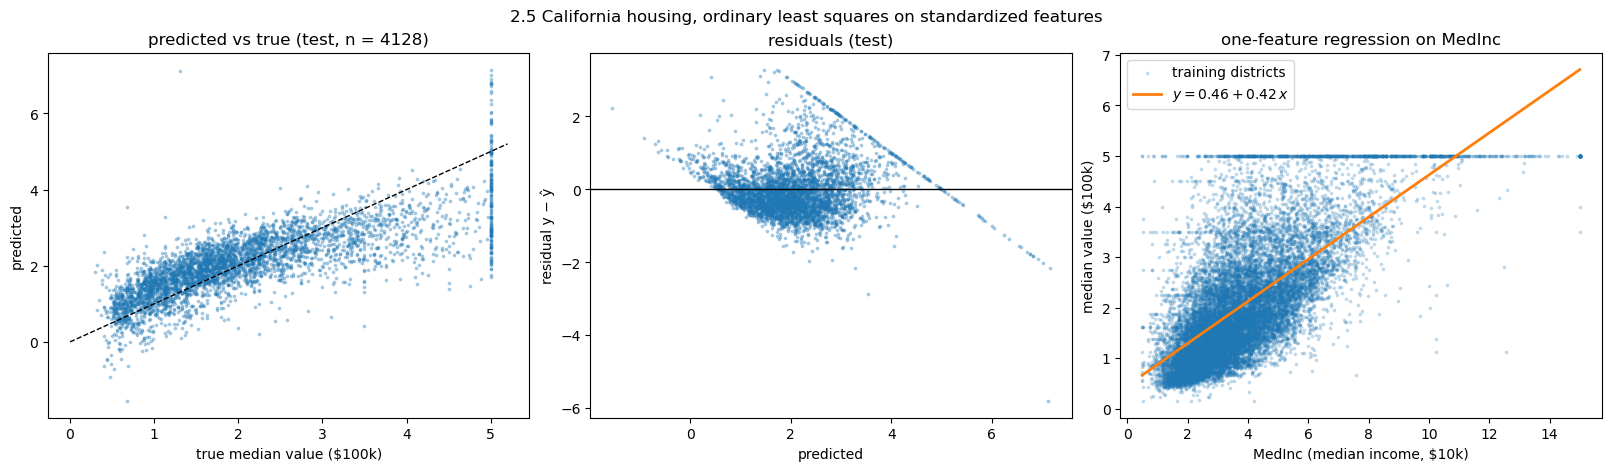

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6), constrained_layout=True)
ax = axes[0]
ax.scatter(y25te, pred25, s=3, alpha=0.3)
ax.plot([0, 5.2], [0, 5.2], "k--", lw=1)
ax.set(xlabel=r"true median value (\$100k)", ylabel="predicted", title=f"predicted vs true (test, n = {te25.size})")
ax = axes[1]
ax.scatter(pred25, res25, s=3, alpha=0.3)
ax.axhline(0, color="k", lw=1)
ax.set(xlabel="predicted", ylabel="residual y − ŷ", title="residuals (test)")
ax = axes[2]
ax.scatter(x1, y25, s=3, alpha=0.2, label="training districts")
xs = np.linspace(x1.min(), x1.max(), 2)
ax.plot(xs, w1[0] + w1[1] * xs, "C1", lw=2, label=rf"$y = {w1[0]:.2f} + {w1[1]:.2f}\,x$")
ax.set(xlabel=rf"{names_c[best]} (median income, \$10k)", ylabel=r"median value (\$100k)", title=f"one-feature regression on {names_c[best]}")
ax.legend()
fig.suptitle("2.5 California housing, ordinary least squares on standardized features")
mc.savefig(fig, "2_5_housing")
plt.show()

**Interpretation.** Least squares gives test MSE $0.515\pm0.018$ and $R^2=0.605$, close to training (0.527, 0.606), so the error is bias rather than overfitting; median income alone reaches $R^2=0.468$. The diagonal stripe in the residuals comes from the \$500k cap (5% of districts, underpredicted by 1.08 on average). Coefficients are effects with the other features held fixed. Latitude and longitude ($-0.915$, $-0.884$, correlated $-0.93$) only mean something together, and AveRooms and AveBedrms (correlated $+0.86$) both have the opposite sign of their marginal correlation with price.

## 2.6 Library comparison and timing

Protocol (DECISIONS row 14):
- BLAS pinned to 1 thread with `threadpoolctl`;
- data generated outside the timed region;
- one warm-up call, then the median of 20 repeats (5 in FAST mode);
- $N=10^3\dots10^6$ at $d=20$, and $d=10\dots1000$ at $N=10^4$ (FAST: $N\le10^5$, $d\le300$).

The full-scale timings come from a `FAST=0` run cached in `cache/full/2_6_timing.npz`; FAST mode plots that cache when it exists.
GD and L-BFGS stop at $\lVert\nabla E_{in}\rVert\le10^{-8}$ / tol $10^{-10}$. GD's time includes computing $L$ (an SVD), which is part of the method.

In [14]:
# Library comparison: coefficients vs LinearRegression
from sklearn.linear_model import LinearRegression

rng = mc.rng_for("2_6")
Xr = rng.standard_normal((10**4, 20))
Xb = mc.add_bias(Xr)
y = Xb @ rng.standard_normal(21) + 0.1 * rng.standard_normal(10**4)
lr = LinearRegression().fit(Xr, y)
w_sk = np.r_[lr.intercept_, lr.coef_]
lg = lambda w: mc.linreg_loss_grad(w, Xb, y)  # noqa: E731
ours = {
    "inv": mc.solve_normal_inv(Xb, y),
    "pinv": mc.solve_pinv_svd(Xb, y),
    "qr": mc.solve_qr(Xb, y),
    "lstsq": mc.solve_lstsq(Xb, y),
    "GD": mc.gradient_descent(lg, np.zeros(21), 1 / mc.lipschitz_linreg(Xb), 10**4, tol=1e-8)[0],
    "L-BFGS": mc.lbfgs(lg, np.zeros(21), tol=1e-10)[0],
}
print("N = 10^4, d = 20: max |w_ours - w_sklearn| (intercept + 20 coefficients)")
for name, w in ours.items():
    print(f"  {name:<7} {np.max(np.abs(w - w_sk)):.1e}")

N = 10^4, d = 20: max |w_ours - w_sklearn| (intercept + 20 coefficients)
  inv     7.5e-15
  pinv    1.1e-14
  qr      8.7e-15
  lstsq   1.2e-14
  GD      9.8e-10
  L-BFGS  8.3e-09


In [15]:
# Library comparison: timing
from sklearn.linear_model import LinearRegression
from threadpoolctl import threadpool_info, threadpool_limits

print("BLAS:", [(i["internal_api"], i.get("version"), i["num_threads"]) for i in threadpool_info()], "-> pinned to 1 thread")
REPEATS = 5 if FAST else 20
N_TIME = [10**3, 3 * 10**3, 10**4, 3 * 10**4, 10**5] + ([] if FAST else [3 * 10**5, 10**6])
D_TIME = [10, 30, 100, 300] + ([] if FAST else [1000])


def gd_fit(Xb, y):
    lg = lambda w: mc.linreg_loss_grad(w, Xb, y)  # noqa: E731
    return mc.gradient_descent(lg, np.zeros(Xb.shape[1]), 1 / mc.lipschitz_linreg(Xb), 10**4, tol=1e-8)[0]


METHODS = {
    "inv": lambda Xb, Xr, y: mc.solve_normal_inv(Xb, y),
    "pinv": lambda Xb, Xr, y: mc.solve_pinv_svd(Xb, y),
    "qr": lambda Xb, Xr, y: mc.solve_qr(Xb, y),
    "lstsq": lambda Xb, Xr, y: mc.solve_lstsq(Xb, y),
    "GD": lambda Xb, Xr, y: gd_fit(Xb, y),
    "L-BFGS": lambda Xb, Xr, y: mc.lbfgs(lambda w: mc.linreg_loss_grad(w, Xb, y), np.zeros(Xb.shape[1]), tol=1e-10)[0],
    "sklearn": lambda Xb, Xr, y: LinearRegression().fit(Xr, y),
}


def median_time(fn, repeats):
    fn()                                     # warm-up, not timed
    times = []
    for _ in range(repeats):
        t0 = time.perf_counter()
        fn()
        times.append(time.perf_counter() - t0)
    return float(np.median(times))


def sweep(shapes, rng):
    times = {m: [] for m in METHODS}
    for N, d_ in shapes:
        Xr = rng.standard_normal((N, d_))   # data generation is outside the timed region
        Xb = mc.add_bias(Xr)
        y = Xb @ rng.standard_normal(d_ + 1) + 0.1 * rng.standard_normal(N)
        for m, fn in METHODS.items():
            times[m].append(median_time(lambda: fn(Xb, Xr, y), REPEATS))
        del Xr, Xb, y
    return {m: np.array(t) for m, t in times.items()}


t0 = time.perf_counter()
with threadpool_limits(limits=1):
    t_N = sweep([(N, 20) for N in N_TIME], mc.rng_for("2_6_N"))
    t_d = sweep([(10**4, d_) for d_ in D_TIME], mc.rng_for("2_6_d"))
print(f"timing sweeps: {time.perf_counter() - t0:.1f} s ({REPEATS} repeats)")
if not FAST:
    mc.save_cache("2_6_timing", N=np.array(N_TIME), d=np.array(D_TIME), repeats=REPEATS,
                  **{f"tN_{m}": t for m, t in t_N.items()}, **{f"td_{m}": t for m, t in t_d.items()})

BLAS: [('openblas', '0.3.29', 12), ('openmp', None, 12)] -> pinned to 1 thread


timing sweeps: 5.7 s (5 repeats)


timings plotted from: full run, median of 20 repeats
method    slope in N (d=20)  slope in d (N=1e4)  t at largest N  t at largest d
inv                    1.01                1.93        0.0283 s          0.24 s
pinv                   1.18                1.60         0.465 s          1.66 s
qr                     1.27                1.43         0.561 s          1.01 s
lstsq                  1.13                1.51         0.204 s         0.678 s
GD                     1.08                1.52         0.252 s         0.803 s
L-BFGS                 0.94                1.25        0.0463 s        0.0462 s
sklearn                1.14                1.50         0.233 s         0.691 s


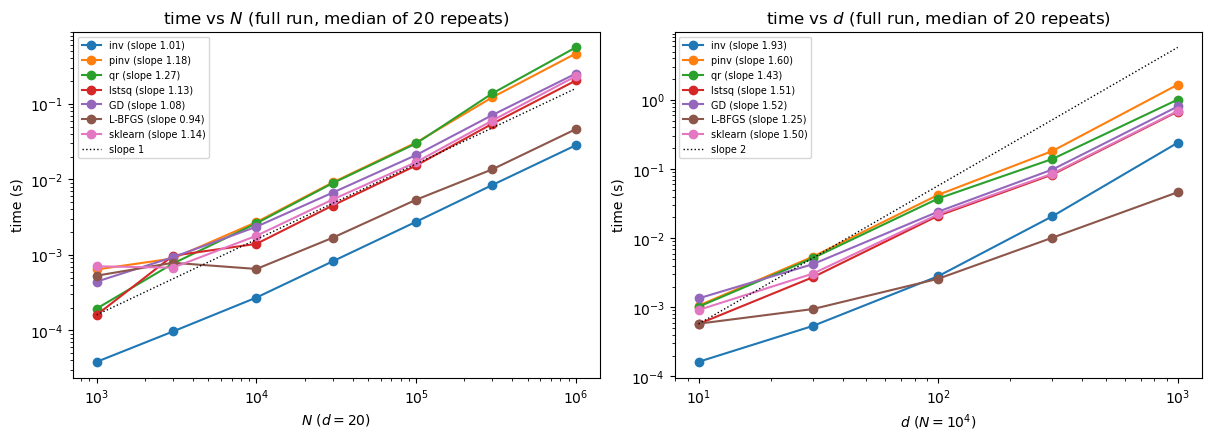

In [16]:
full = mc.load_full_cache("2_6_timing") if FAST else None
if full is not None:
    xN, xd, rep = full["N"], full["d"], int(full["repeats"])
    tN = {m: full[f"tN_{m}"] for m in METHODS}
    td = {m: full[f"td_{m}"] for m in METHODS}
    label = f"full run, median of {rep} repeats"
else:
    xN, xd, tN, td = np.array(N_TIME), np.array(D_TIME), t_N, t_d
    label = f"{'FAST' if FAST else 'full'} run, median of {REPEATS} repeats"

fig, axes = plt.subplots(1, 2, figsize=(12, 4.3), constrained_layout=True)
print(f"timings plotted from: {label}")
print(f"{'method':<8}{'slope in N (d=20)':>19}{'slope in d (N=1e4)':>20}{'t at largest N':>16}{'t at largest d':>16}")
for c, m in enumerate(METHODS):
    sN = np.polyfit(np.log(xN[-3:]), np.log(tN[m][-3:]), 1)[0]
    sd = np.polyfit(np.log(xd[-3:]), np.log(td[m][-3:]), 1)[0]
    axes[0].loglog(xN, tN[m], "o-", color=f"C{c}", label=f"{m} (slope {sN:.2f})")
    axes[1].loglog(xd, td[m], "o-", color=f"C{c}", label=f"{m} (slope {sd:.2f})")
    print(f"{m:<8}{sN:>19.2f}{sd:>20.2f}{tN[m][-1]:>14.3g} s{td[m][-1]:>14.3g} s")
ref = tN["lstsq"]
axes[0].loglog(xN, ref[0] * xN / xN[0], "k:", lw=1, label="slope 1")
ref = td["lstsq"]
axes[1].loglog(xd, ref[0] * (xd / xd[0]) ** 2, "k:", lw=1, label="slope 2")
axes[0].set(xlabel="$N$ ($d = 20$)", ylabel="time (s)", title=f"time vs $N$ ({label})")
axes[1].set(xlabel="$d$ ($N = 10^4$)", ylabel="time (s)", title=f"time vs $d$ ({label})")
for ax in axes:
    ax.legend(fontsize=7)
mc.savefig(fig, "2_6_timing")
plt.show()

**Interpretation.** The direct solvers match `LinearRegression` to $\le1.2\times10^{-14}$ and GD and L-BFGS to their tolerances ($9.8\times10^{-10}$, $8.3\times10^{-9}$), since scikit-learn calls the same LAPACK routines. Timing slopes in $N$ are 0.94–1.27, so cost is linear in $N$. In $d$ only `inv` reaches the predicted slope 2 (1.93), while BLAS-3 efficiency keeps the others at 1.25–1.60. `inv` is the fastest at $N=10^6$ (0.028 s against 0.20 s for `lstsq`), but 2.3 shows it is the least accurate.

## 2.7 Linear regression for classification

The 1.4 digit features and split. $\mathrm{sign}(w_{lin}^Tx)$ against Pocket from $w_0=0$ and from $w_0=w_{lin}$ (100 runs each).

In [17]:
from sklearn.datasets import load_digits  # data loading only (R1)

dig = load_digits()
keep = np.isin(dig.target, [1, 5])
F_all = mc.intensity_symmetry(dig.images[keep] / 16.0)
y_all = np.where(dig.target[keep] == 1, 1.0, -1.0)
tr27, te27 = mc.stratified_split(y_all, 0.3, mc.rng_for("1_4_split"))  # same split as 1.4
F_tr, prm27 = mc.minmax_scale(F_all[tr27])
Z_tr, Z_te = mc.add_bias(F_tr), mc.add_bias(mc.apply_minmax(F_all[te27], prm27))
y_tr, y_te = y_all[tr27], y_all[te27]

w_lin = mc.solve_lstsq(Z_tr, y_tr)
res27 = {"linear regression": (w_lin[None], np.array([mc.ein_01(w_lin, Z_tr, y_tr)]), np.array([mc.ein_01(w_lin, Z_te, y_te)]))}
for name, w0 in (("Pocket, w0 = 0", None), ("Pocket, w0 = w_lin", w_lin)):
    rng27 = mc.rng_for(f"2_7_linear_{'lin' if w0 is not None else 'zero'}")
    runs = [mc.pocket(Z_tr, y_tr, rng27, T=1000, w0=w0) for _ in range(100)]
    W = np.array([r[0] for r in runs])
    res27[name] = (W, np.array([r[2][-1] for r in runs]), np.array([mc.ein_01(w, Z_te, y_te) for w in W]))


def fmt(a):
    return f"{a[0]:.4f}" if a.size == 1 else "{:.4f} ± {:.4f}".format(*mc.mean_se(a))


for name, (W, ein, etest) in res27.items():
    print(f"{name:<20} Ein {fmt(ein)}   Etest {fmt(etest)}")

linear regression    Ein 0.4213   Etest 0.3818
Pocket, w0 = 0       Ein 0.3548 ± 0.0009   Etest 0.3504 ± 0.0014
Pocket, w0 = w_lin   Ein 0.3492 ± 0.0013   Etest 0.3401 ± 0.0021


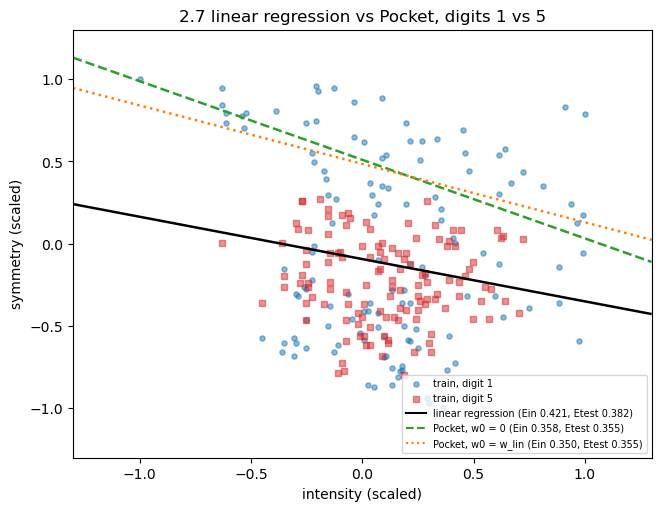

In [18]:
g1, g2 = np.meshgrid(np.linspace(-1.3, 1.3, 400), np.linspace(-1.3, 1.3, 400))
G = mc.add_bias(np.column_stack([g1.ravel(), g2.ravel()]))
fig, ax = plt.subplots(figsize=(6.5, 5), constrained_layout=True)
for lab, mk, col in ((1, "o", "C0"), (-1, "s", "C3")):
    ax.scatter(*F_tr[y_tr == lab].T, marker=mk, s=14, c=col, alpha=0.5, label=f"train, digit {1 if lab == 1 else 5}")
for (name, (W, ein, etest)), col, ls in zip(res27.items(), ("k", "C2", "C1"), ("-", "--", ":")):
    rep = int(np.argsort(ein, kind="stable")[ein.size // 2])  # median-Ein run
    ax.contour(g1, g2, (G @ W[rep]).reshape(g1.shape), levels=[0], colors=col, linestyles=ls, linewidths=1.8)
    ax.plot([], [], color=col, ls=ls, label=f"{name} (Ein {ein[rep]:.3f}, Etest {etest[rep]:.3f})")
ax.set(xlim=(-1.3, 1.3), ylim=(-1.3, 1.3), xlabel="intensity (scaled)", ylabel="symmetry (scaled)",
       title="2.7 linear regression vs Pocket, digits 1 vs 5")
ax.legend(fontsize=7, loc="lower right")
mc.savefig(fig, "2_7_linreg_classification")
plt.show()

**Interpretation.** $\mathrm{sign}(w_{lin}^Tx)$ has $E_{in}=0.421$, worse than Pocket ($0.355\pm0.001$), because squared loss also penalizes correct points far from the boundary. As Pocket's start it helps a little ($E_{in}=0.349\pm0.001$, $E_{test}=0.340\pm0.002$), and Pocket can never end worse than its start.